# Lab 1 — Delineate the West Rapti basin  (interactive-first)

**Objective:** stand up a delineated case basin on the canonical WA+ grid, and the BASIN skeleton.

**The live map comes first.** After a one-time setup:

1. **Pick** the outlet on a zoomable Earth-Engine map and **preview** its basin instantly on a light 500 m DEM (§3) — try as many outlets as you like;
2. **download** the 90 m DEM for the chosen basin only, **fill** it and check it (§4);
3. **refine** the outlet at 90 m and export the map to PDF (§5);
4. **freeze** it: paste the outlet into CONFIG and **Restart & Run All** (§6–9) for Labs 2–6.

Reusable logic lives in `west_rapti.py`; this notebook only calls it. Runs on **Google Colab** and locally.

## 1 · Setup — run this first  (mounts Drive, installs packages, loads `west_rapti`)

In [1]:
import os, sys, shutil
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive; drive.mount('/content/drive')
    # >>> EDIT: the folder on your Drive holding west_rapti.py and get_dem.py <<<
    KW_DIR = '/content/drive/MyDrive/west_rapti'
    get_ipython().system('pip -q install dem-stitcher pysheds rioxarray geemap geedim scikit-image rasterio')
    for f in ('get_dem.py',):
        src = os.path.join(KW_DIR, f)
        if os.path.exists(src) and not os.path.exists(f): shutil.copy(src, f)
else:
    KW_DIR = '.'
OUT_DIR = os.path.join(KW_DIR, 'outputs') if IN_COLAB else 'outputs'

# --- always load the engine from KW_DIR (Drive), never a stale copy elsewhere ---
_kw = os.path.abspath(KW_DIR)
if os.path.abspath('.') != _kw:
    for _f in ('west_rapti.py', 'westrapti_prep.py'):
        if os.path.exists(_f): os.remove(_f)
for _p in (KW_DIR, _kw):
    while _p in sys.path: sys.path.remove(_p)
sys.path.insert(0, _kw)
for _m in ('west_rapti', 'westrapti_prep'): sys.modules.pop(_m, None)
# --- participant settings (written once by 00_Setup.ipynb) ---
import json as _json
_pj = os.path.join(KW_DIR, 'participant.json')
PARTICIPANT = _json.load(open(_pj)) if os.path.exists(_pj) else {}
EE_PROJECT = PARTICIPANT.get('ee_project', '')
if not EE_PROJECT:
    print('⚠️  No Earth Engine project set — run 00_Setup.ipynb first (or set EE_PROJECT in CONFIG).')

%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, rioxarray
from matplotlib.colors import LogNorm
from pathlib import Path
import importlib, west_rapti as kw
importlib.reload(kw)
print('Running on', 'Colab' if IN_COLAB else 'local', '| outputs ->', OUT_DIR)

Mounted at /content/drive
Running on Colab | outputs -> /content/drive/MyDrive/west_rapti/outputs


## 2 · ⭐ SET THESE TWO THINGS

Everything else can stay on its defaults. You only have to set:

1. **`EE_PROJECT`** — your Google **Earth Engine project id** (the live map and the GLO-30 DEM come from
   Earth Engine). Get it at [earthengine.google.com](https://earthengine.google.com) → your Cloud project.
2. **`GAUGE_LON, GAUGE_LAT`** — the **outlet** where your basin drains out (decimal degrees, **lon first**).
   This is a *starting point* — you can also drag/click it on the map in §4 and read the coordinates back.

`BBOX` just needs to be a box a little larger than your basin (used to load the map and the DEM).

In [2]:
# ================== ⭐ EDIT THESE TWO ==================
EE_PROJECT = EE_PROJECT or 'your-ee-project-id'             # ⭐ 1) your Earth Engine project id
GAUGE_LON, GAUGE_LAT = 81.372025, 28.172720  # ⭐ 2) OUTLET (lon, lat) — West Rapti at Kusum (DHM Q375); drag on the map to change
# ======================================================

# --- map / DEM extent and grid (usually fine as-is) ---
BBOX     = [80.00, 27.30, 84.80, 28.90]  # [W,S,E,N] deg — SEARCH box: map + coarse pass (can be generous)
UTM       = "EPSG:32644"                   # UTM 44N — correct for the West Rapti (~82°E)
ACC_MIN  = 5000                           # min upstream cells to snap the outlet to a 'stream' (smaller catchment → lower threshold)
DEM_SOURCE = "gee"                        # "gee" (Earth Engine GLO-30) | "auto" (key-free download) | "own"
DEM_IN   = "glo30.tif"                    # working DEM filename
DEM_OWN  = ""                             # path to your DEM when DEM_SOURCE=="own" ("" = upload on Colab)
DEM_RES  = 90                             # delineation resolution (m); 30 for a small tributary
WA_RES   = 300                            # canonical WA+ grid (m)


# --- faster DEM download (matters for large basins) ---
TWO_PASS   = True      # pass 1: 500 m DEM of BBOX → find the basin; pass 2: download ONLY basin + buffer at DEM_RES
COARSE_RES = 500       # pass-1 resolution (m) — a few MB even for a huge box
BUFFER_KM  = 10        # margin around the pass-1 basin (covers ridge errors at 500 m)
DEM_DTYPE  = "int16"   # half the size of float32; 1 m vertical steps are fine for delineation ("float32" for very flat plains)
DL_THREADS = 8         # parallel tile downloads (geedim)
DL_TILE_MB = 16        # tile size; lower (8, 4) if Earth Engine reports memory / 'too large' errors
DL_METHOD  = "direct"  # "direct" = tiles into this session | "drive" = server-side export to Drive (very large basins, no time-outs)
USE_CACHE  = True      # reuse DEMs already on Drive: Restart & Run All does not download again

# --- hydrological conditioning ---
FILL_DEM   = True      # delineation always runs on the filled DEM; False only to demonstrate why filling matters
print(f"outlet = {GAUGE_LON}, {GAUGE_LAT} | EE project = {EE_PROJECT} | DEM via {DEM_SOURCE} "
      f"({'two-pass' if TWO_PASS and DEM_SOURCE=='gee' else 'single pass'}, {DL_METHOD})")

# --- canonical WA+ grid ---
GRID_TE = None   # None = snap the grid to the DEM extent. To keep an EXISTING grid (so Labs 2–6 outputs stay valid),
                 # paste its 'te' from gridspec.json, e.g. [400800.0, 3019500.0, 876300.0, 3205500.0]

outlet = 81.372025, 28.17272 | EE project = gee-training-nepal-wecs-2026 | DEM via gee (two-pass, direct)


### Google Earth Engine API Key / Project Setup

Since `DEM_SOURCE` is set to `gee`, the notebook attempts to fetch DEM data from Google Earth Engine. This requires a valid Google Cloud Project ID with the Earth Engine API enabled and, in some cases, billing enabled. The `EE_PROJECT` variable (currently your Earth Engine project ID (set once in `00_Setup.ipynb`; it is stored in `participant.json`)) in the previous cell specifies this project.

If you're encountering an API key error related to Earth Engine, please ensure the following:

1.  **Project ID:** Double-check that your Earth Engine project ID (set once in `00_Setup.ipynb`; it is stored in `participant.json`) is indeed your correct Google Cloud Project ID where you have enabled the Earth Engine API.
2.  **Earth Engine API Enabled:** Visit the [Google Cloud Console](https://console.cloud.google.com/) for your project, navigate to 'APIs & Services' -> 'Enabled APIs & Services', and search for 'Earth Engine API'. Make sure it's enabled.
3.  **Authentication:** The `ee.Authenticate()` call in cell `7caf945b` is meant to handle authentication. If you're running this for the first time or if your credentials have expired, you might be prompted to follow a link and paste an authorization code. Ensure this process completes successfully.
4.  **Billing:** While basic Earth Engine usage is free, extensive use or certain datasets might require a linked billing account. Verify that your Google Cloud Project has billing set up if necessary.

After verifying these steps, please try running the notebook again.

## 3 · 🖱️ Pick the outlet and preview the basin  (500 m — seconds)

A **light 500 m DEM** of the whole `BBOX` (a few MB) lets you preview the basin of **any** outlet instantly — no big download yet.

Drag the **orange marker** onto the river at your gauge (or **click** the map), set **ACC_MIN** (the preview re-runs when you release the slider), or press **Preview basin**. Try as many outlets as you like; the **last preview** is the outlet §4 downloads for.

> The 500 m basin is approximate — ridgelines shift slightly and small tributaries may snap differently. §5 refines it at 90 m, and §6 freezes the 90 m result.

**What ACC_MIN does.** It is the drainage area (in cells) a channel needs to count as a *stream*. The light-blue lines show the stream network for the current value; the outlet snaps to the nearest stream. On the main river every smaller value gives the **same basin** — ACC_MIN only changes the result when the marker sits off the channel or near a tributary junction.

### 3a · Hydrology — delineation always runs on a **filled** DEM

Real DEMs contain **sinks**: single-cell pits (noise) and closed depressions (artefacts, bridges, real lakes). Water routed with D8 stops in a sink, so upstream area is **cut off** from the outlet and the basin comes out too small. `kw.delineate` therefore **fills pits → fills depressions → resolves flats** before routing flow, and caches the result per DEM file so every *Preview* / *Delineate* click is instant.

§4b then **proves** it with `kw.check_conditioning`, an independent re-fill that must find nothing left to fill.

In [3]:
import west_rapti as kw, numpy as np, rasterio
from pyproj import Transformer
assert hasattr(kw, 'check_conditioning'), (f'{kw.__file__} is an OLD west_rapti.py. Re-run 00_Setup.ipynb '
                                           '(it refreshes the engine), then Runtime → Restart session and Run all.')
delineate_filled = kw.delineate          # fills pits/depressions + resolves flats, cached per DEM file
print('engine:', kw.__file__, '| kw.delineate (filled DEM, cached) | check: kw.check_conditioning')

engine: /content/drive/MyDrive/west_rapti/west_rapti.py | kw.delineate (filled DEM, cached) | check: kw.check_conditioning


In [4]:
import time, json, hashlib, shutil, rasterio
from pathlib import Path
CACHE_DIR = Path(OUT_DIR) / "dem_cache"; CACHE_DIR.mkdir(parents=True, exist_ok=True)
def _key(*a): return hashlib.md5(json.dumps(a).encode()).hexdigest()[:10]
def _mb(p):   return os.path.getsize(p) / 1e6
def _mpx(b, res):   # pixels in a lon/lat box at res metres
    return (b[2]-b[0]) * 111e3 * np.cos(np.radians((b[1]+b[3])/2)) * (b[3]-b[1]) * 111e3 / res**2

def gee_dem(res, crs, average=True):
    """GLO-30 mosaic. With average=True, coarser outputs average the 30 m cells (not nearest-pixel).
    No .reproject() here: the download sets crs/scale for the clipped box only — reprojecting the
    whole unbounded mosaic is what triggers 'Reprojection output too large'."""
    col = ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1").select("DEM")
    img = col.mosaic().setDefaultProjection(col.first().projection())
    if average and res > 30:
        img = img.reduceResolution(ee.Reducer.mean(), maxPixels=1024)
    return img

def export_via_drive(img, local, region, res, crs):
    """Server-side export: no session time-outs, any size. Big exports arrive as tiles and are mosaicked."""
    name, folder = Path(local).stem, "wa_dem_exports"
    img = img.toInt16() if DEM_DTYPE == "int16" else img.toFloat()
    task = ee.batch.Export.image.toDrive(image=img, description=name, folder=folder, fileNamePrefix=name,
                                         region=region, scale=res, crs=crs, maxPixels=1e11, fileFormat="GeoTIFF")
    task.start(); print("  export running on Google's servers", end="", flush=True)
    while task.active(): time.sleep(15); print(".", end="", flush=True)
    st = task.status(); print(" ", st["state"])
    if st["state"] != "COMPLETED": raise RuntimeError(st.get("error_message", st))
    if not IN_COLAB:
        raise SystemExit(f"Export done — download {name}*.tif from Drive folder '{folder}', then use DEM_SOURCE='own'.")
    ddir, parts = Path("/content/drive/MyDrive") / folder, []
    for _ in range(40):                                     # Drive can take a minute to show new files
        parts = sorted(ddir.glob(f"{name}*.tif"))
        if parts: break
        time.sleep(15)
    if not parts: raise RuntimeError("Export finished but the file is not in Drive yet — re-run this cell in a minute.")
    if len(parts) == 1: shutil.copy(parts[0], local); return
    from rasterio.merge import merge
    srcs = [rasterio.open(p) for p in parts]; arr, tr = merge(srcs)
    prof = srcs[0].profile; prof.update(height=arr.shape[1], width=arr.shape[2], transform=tr)
    with rasterio.open(local, "w", **prof) as d: d.write(arr)

def fetch(img, path, bbox, res, crs):
    """Download to fast local disk, then keep a copy in the Drive cache."""
    region = ee.Geometry.Rectangle(bbox)
    local = Path("/content" if IN_COLAB else ".") / Path(path).name
    t = time.time()
    img = img.clip(region)                                   # bound the computation to the download box
    if DL_METHOD == "drive":
        export_via_drive(img, local, region, res, crs)
    else:
        try:
            geemap.download_ee_image(img, str(local), region=region, crs=crs, scale=res, dtype=DEM_DTYPE,
                                     num_threads=DL_THREADS, max_tile_size=DL_TILE_MB)
        except Exception as e:                               # fallback: bilinear resampling, no server-side averaging
            print(f"  averaged download failed ({str(e)[:120]}) — retrying with bilinear resampling")
            geemap.download_ee_image(gee_dem(res, crs, average=False).clip(region), str(local), region=region,
                                     crs=crs, scale=res, dtype=DEM_DTYPE, resampling="bilinear",
                                     num_threads=DL_THREADS, max_tile_size=DL_TILE_MB)
    if Path(path).resolve() != local.resolve(): shutil.copy(local, path)
    print(f"  {Path(path).name}: {_mb(path):.1f} MB in {time.time()-t:.0f} s")

def basin_bbox(mask, T, crs, buffer_m, clip_to):
    """lon/lat box around a basin mask (+ buffer); also reports whether the basin touches the raster edge."""
    rows, cols = np.nonzero(mask)
    if rows.size == 0: return None, False
    touches = rows.min() == 0 or cols.min() == 0 or rows.max() == mask.shape[0]-1 or cols.max() == mask.shape[1]-1
    x0 = T.c + T.a * cols.min() - buffer_m;  x1 = T.c + T.a * (cols.max()+1) + buffer_m
    y1 = T.f + T.e * rows.min() + buffer_m;  y0 = T.f + T.e * (rows.max()+1) - buffer_m
    to_ll = Transformer.from_crs(crs, "EPSG:4326", always_xy=True).transform
    pts = [to_ll(x, y) for x in np.linspace(x0, x1, 5) for y in np.linspace(y0, y1, 5)]
    lo, la = [p[0] for p in pts], [p[1] for p in pts]
    bb = [max(clip_to[0], min(lo)), max(clip_to[1], min(la)), min(clip_to[2], max(lo)), min(clip_to[3], max(la))]
    return [round(v, 4) for v in bb], touches

# ---- EE session (map tiles + downloads). 'auto'/'own' still work for the DEM without Earth Engine. ----
EE_OK = False
try:
    import ee, geemap
    try: ee.Initialize(project=EE_PROJECT)
    except Exception: ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
    EE_OK = True
except Exception as e:
    print("Earth Engine not available:", e)

# ---- pass 1: light DEM of the whole BBOX, for previews ----
COARSE_DEM = str(CACHE_DIR / f"coarse_{_key(BBOX, COARSE_RES, UTM, DEM_DTYPE, DEM_SOURCE)}.tif")
if USE_CACHE and Path(COARSE_DEM).exists():
    print("Preview DEM: using cached", Path(COARSE_DEM).name)
elif DEM_SOURCE == "gee":
    print(f"Preview DEM: {COARSE_RES} m of the whole BBOX (~{_mpx(BBOX, COARSE_RES)/1e6:.2f} M pixels)")
    fetch(gee_dem(COARSE_RES, UTM), COARSE_DEM, BBOX, COARSE_RES, UTM)
else:                                              # 'own' / 'auto': get the full DEM once, then coarsen it
    if DEM_SOURCE == "own":
        if DEM_OWN: DEM_IN = DEM_OWN
        elif IN_COLAB:
            from google.colab import files; DEM_IN = list(files.upload().keys())[0]
        else: raise SystemExit("Set DEM_OWN to your DEM path.")
    else:
        import get_dem
        if not Path(DEM_IN).exists(): get_dem.fetch_dem(BBOX, DEM_IN)
    kw.reproject_dem(DEM_IN, UTM, COARSE_RES, COARSE_DEM)
ACC_SCALE = (DEM_RES / COARSE_RES) ** 2            # ACC_MIN is in DEM_RES cells → same upstream AREA at 500 m
print("preview DEM ready:", Path(COARSE_DEM).name)

Preview DEM: using cached coarse_3cdb149080.tif
preview DEM ready: coarse_3cdb149080.tif


In [5]:
# --- pick + preview: every click delineates on the (filled) 500 m DEM, instantly ---
import ipywidgets as W
from IPython.display import display
from ipyleaflet import Marker, CircleMarker
from rasterio.features import shapes
from shapely.geometry import shape, mapping
from shapely.ops import unary_union, transform as shp_transform

to_ll = Transformer.from_crs(UTM, "EPSG:4326", always_xy=True).transform

# --- river network for the current ACC_MIN: a line from every stream cell to its downstream (D8) cell ---
_D8 = {64: (-1, 0), 128: (-1, 1), 1: (0, 1), 2: (1, 1), 4: (1, 0), 8: (1, -1), 16: (0, -1), 32: (-1, -1)}
def streams_geojson(acc, fdir, tif, thr, max_seg=20000):
    with rasterio.open(tif) as s: tr = s.transform
    acc = np.asarray(acc); fd = np.asarray(fdir)
    rows, cols = np.nonzero(acc > thr)
    if rows.size > max_seg:                                    # keep the biggest channels for a light map
        keep = np.argsort(acc[rows, cols])[-max_seg:]; rows, cols = rows[keep], cols[keep]
    d = np.array([_D8.get(int(v), (0, 0)) for v in fd[rows, cols]])
    ok = (d != 0).any(axis=1); rows, cols, d = rows[ok], cols[ok], d[ok]
    x1, y1 = tr * (cols + 0.5, rows + 0.5); x2, y2 = tr * (cols + d[:, 1] + 0.5, rows + d[:, 0] + 0.5)
    lo1, la1 = to_ll(np.asarray(x1), np.asarray(y1)); lo2, la2 = to_ll(np.asarray(x2), np.asarray(y2))
    lines = [[[a, b], [c_, e]] for a, b, c_, e in zip(lo1, la1, lo2, la2)]
    return {"type": "Feature", "properties": {}, "geometry": {"type": "MultiLineString", "coordinates": lines}}

def snap_report(res, tif, thr):
    """What the outlet snapped to: the channel's own drainage area vs the stream threshold."""
    with rasterio.open(tif) as s: tr = s.transform
    cell_km2 = abs(tr.a * tr.e) / 1e6
    sx, sy = res['snap']; col = int((float(sx) - tr.c) / tr.a); row = int((float(sy) - tr.f) / tr.e)
    up = float(np.asarray(res['acc'])[row, col]) * cell_km2
    jump = float(np.hypot(float(sx) - res['gauge'][0], float(sy) - res['gauge'][1])) / 1000
    msg = (f"snapped to a channel draining ≈ {up:,.0f} km²  (stream threshold ACC_MIN = {thr:,} cells ≈ {thr * cell_km2:,.1f} km²)."
           + ("  On the main river, any smaller ACC_MIN gives the same basin — it matters near tributary junctions."
              if up > 20 * thr * cell_km2 else ""))
    if jump > 1.0:
        msg += (f"\n   ⚠️ the outlet moved {jump:.1f} km from your marker to reach a big-enough channel — "
                "lower ACC_MIN or move the marker onto the river.")
    return msg
def mask_to_geojson(mask, tif):
    with rasterio.open(tif) as s: tr = s.transform
    geoms = [shape(g) for g, v in shapes(mask, mask=mask == 1, transform=tr) if v == 1]
    return {"type": "Feature", "properties": {}, "geometry": mapping(shp_transform(to_ll, unary_union(geoms)))}

P = geemap.Map(basemap='Esri.WorldImagery', center=[GAUGE_LAT, GAUGE_LON], zoom=9)
if EE_OK:
    region = ee.Geometry.Rectangle(BBOX)
    dem_ee = ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1").select("DEM").mosaic()
    P.addLayer(ee.Terrain.hillshade(dem_ee), {"min": 0, "max": 255}, "Hillshade", True)
    P.addLayer(ee.FeatureCollection("WWF/HydroSHEDS/v1/FreeFlowingRivers").filterBounds(region),
               {"color": "1f78ff"}, "Rivers (HydroSHEDS)", True)
    P.addLayer(region, {"color": "ffffff"}, "BBOX (preview area)", False)

pick = {"lon": GAUGE_LON, "lat": GAUGE_LAT}
mk = Marker(location=(GAUGE_LAT, GAUGE_LON), draggable=True, title="Outlet — drag onto the river")
P.add(mk)
def _mv(change): pick["lat"], pick["lon"] = float(mk.location[0]), float(mk.location[1])
mk.observe(_mv, names="location")
def _clk(**k):
    if k.get("type") == "click": mk.location = (k["coordinates"][0], k["coordinates"][1])
P.on_interaction(_clk)

acc_p = W.FloatLogSlider(value=ACC_MIN, base=10, min=3, max=6.5, step=0.1, description="ACC_MIN",
                         readout_format=".0f", continuous_update=False)   # re-runs when released
b_prev = W.Button(description=f"Preview basin ({COARSE_RES} m)", button_style="success", icon="play",
                  layout=W.Layout(width="210px"))
out_p = W.Output()

def _preview(_):
    global GAUGE_LON, GAUGE_LAT, ACC_MIN
    with out_p:
        out_p.clear_output()
        try:
            r = delineate_filled(COARSE_DEM, pick["lon"], pick["lat"], UTM,
                                 max(20, int(acc_p.value * ACC_SCALE)), out=str(CACHE_DIR / "preview_mask.tif"))
        except (ValueError, RuntimeError) as e:
            print("⚠️", e); return
        thr_c = max(20, int(acc_p.value * ACC_SCALE))
        for lyr in list(P.layers):
            if getattr(lyr, "name", "") in ("Preview basin", "Snapped outlet", "Streams (ACC_MIN)"): P.remove_layer(lyr)
        P.add_geojson(streams_geojson(r["acc"], r["fdir"], COARSE_DEM, thr_c), layer_name="Streams (ACC_MIN)",
                      style={"color": "#29B6F6", "weight": 1.5, "opacity": 0.9})
        P.add_geojson(mask_to_geojson(r["mask"], COARSE_DEM), layer_name="Preview basin",
                      style={"color": "#e9a63b", "weight": 2, "fillColor": "#e9a63b", "fillOpacity": 0.15})
        slon, slat = to_ll(*r["snap"])
        P.add(CircleMarker(location=(slat, slon), radius=6, color="red", fill_color="red", name="Snapped outlet"))
        km2 = float(r["mask"].sum()) * COARSE_RES ** 2 / 1e6
        GAUGE_LON, GAUGE_LAT, ACC_MIN = round(pick["lon"], 4), round(pick["lat"], 4), int(acc_p.value)
        print(f"preview basin ≈ {km2:,.0f} km² | snapped outlet lon={slon:.4f}, lat={slat:.4f}")
        print("   " + snap_report(r, COARSE_DEM, thr_c))
        print(f"→ §4 will download for this outlet. To freeze later, put in CONFIG:\n"
              f"   GAUGE_LON, GAUGE_LAT = {GAUGE_LON}, {GAUGE_LAT}   ·   ACC_MIN = {ACC_MIN}")
        if r["mask"][0].any() or r["mask"][-1].any() or r["mask"][:, 0].any() or r["mask"][:, -1].any():
            print("⚠️ the basin touches the BBOX edge — it may be cut off: enlarge BBOX in CONFIG and re-run §3.")

b_prev.on_click(_preview)
acc_p.observe(lambda ch: _preview(None), names='value')   # slider re-runs the preview
display(W.HBox([acc_p, b_prev])); display(out_p)
_preview(None)          # show the CONFIG outlet's basin straight away
P

Output()

Map(center=[28.17272, 81.372025], controls=(WidgetControl(options=['position', 'transparent_bg'], position='to…

### ✅ Checkpoint 1 — preview
Basin sits in the valley, outlet on the gauge, edges follow ridgelines (not a box). Outlet on the wrong small channel → **raise** `ACC_MIN`; empty → **lower** it, or move the marker onto the channel. **Happy? Run §4** — it downloads the 90 m DEM for the outlet you last previewed.

## 4 · DEM at 90 m — only the chosen basin, then fill and check

The outlet from your last preview (or CONFIG, on *Restart & Run All*) defines the download box: the 500 m basin + `BUFFER_KM`, already in UTM, averaged on Google's servers, cached on Drive. For the West Rapti that is roughly **1–2 M pixels** instead of ~93 M for the whole box at 30 m.

> Want to try an outlet **outside** this box later? Go back to §3, preview it, and re-run §4 — it downloads (or reuses) the matching box.

In [6]:
def _download(bbox):
    fpath = CACHE_DIR / f"glo30_{_key(bbox, DEM_RES, UTM, DEM_DTYPE)}.tif"
    print(f"{DEM_RES} m download ≈ {_mpx(bbox, DEM_RES)/1e6:.2f} M pixels "
          f"(full BBOX at 30 m would be ≈ {_mpx(BBOX, 30)/1e6:.0f} M)")
    if USE_CACHE and fpath.exists(): print("  using cached", fpath.name)
    else: fetch(gee_dem(DEM_RES, UTM), fpath, bbox, DEM_RES, UTM)
    return str(fpath)

def _touches_edge(mask, band=5):
    """True if the basin comes within `band` cells of the DEM edge — clipped flow leaves via the edge,
    so a cut basin often stops just short of it rather than touching it."""
    return bool(mask[:band].any() or mask[-band:].any() or mask[:, :band].any() or mask[:, -band:].any())

if DEM_SOURCE == "gee":
    rc = delineate_filled(COARSE_DEM, GAUGE_LON, GAUGE_LAT, UTM, max(20, int(ACC_MIN * ACC_SCALE)),
                          out=str(CACHE_DIR / "coarse_mask.tif"))
    area = float(rc["mask"].sum()) * COARSE_RES ** 2 / 1e6
    fine_bbox, buf = BBOX, BUFFER_KM
    if TWO_PASS:
        with rasterio.open(COARSE_DEM) as s: T = s.transform
        bb, touches = basin_bbox(rc["mask"], T, UTM, buf * 1000, BBOX)
        if touches: print(f"⚠️  the {COARSE_RES} m basin touches the BBOX edge — it may be cut off: enlarge BBOX.")
        if bb and area > 50:
            fine_bbox = bb; print(f"basin ≈ {area:,.0f} km² ({COARSE_RES} m) → download box {fine_bbox}")
        else:
            print(f"could not isolate a basin at {COARSE_RES} m (check the outlet) — downloading the full BBOX.")
    DEM_IN = _download(fine_bbox)
    # guard: the 90 m basin must not be cut by the download box (the 500 m basin can be too small)
    for attempt in range(3):
        kw.reproject_dem(DEM_IN, UTM, DEM_RES, "dem_utm.tif")
        try:
            rf = delineate_filled("dem_utm.tif", GAUGE_LON, GAUGE_LAT, UTM, ACC_MIN, out="_check_mask.tif")
            snap_km = np.hypot(rf["snap"][0] - rf["gauge"][0], rf["snap"][1] - rf["gauge"][1]) / 1000
            area_f = float(rf["mask"].sum()) * DEM_RES ** 2 / 1e6
            why = [w for w, bad in (("reaches the box edge", _touches_edge(rf["mask"])),
                                    (f"outlet snapped {snap_km:.1f} km away", snap_km > 2),
                                    (f"{area_f:,.0f} km² vs {area:,.0f} km² preview", TWO_PASS and area_f < 0.5 * area)) if bad]
        except (ValueError, RuntimeError) as e:
            why = [str(e)]
        cut = bool(why)
        if not cut or fine_bbox == BBOX: break
        buf *= 3
        print(f"⚠️  90 m basin looks cut by the download box ({'; '.join(why)}) — widening the margin to {buf:g} km")
        bb, _ = basin_bbox(rc["mask"], T, UTM, buf * 1000, BBOX)
        fine_bbox = bb if (bb and attempt < 1) else BBOX
        DEM_IN = _download(fine_bbox)
    else:
        print("⚠️  still touching the edge — check the outlet / BBOX.")
    if cut and fine_bbox == BBOX: print("⚠️  the basin touches the BBOX edge: enlarge BBOX in CONFIG.")
else:
    kw.reproject_dem(DEM_IN, UTM, DEM_RES, "dem_utm.tif")
print("terrain ready: dem_utm.tif |", Path("dem_utm.tif").exists())

basin ≈ 3,462 km² (500 m) → download box [81.1117, 27.8568, 82.7136, 28.6435]
90 m download ≈ 1.69 M pixels (full BBOX at 30 m would be ≈ 93 M)


  0%|          |0/1 tiles [00:00<?]

  glo30_d07d624892.tif: 2.4 MB in 19 s
terrain ready: dem_utm.tif | True


elevation range: 121 – 3,567 m


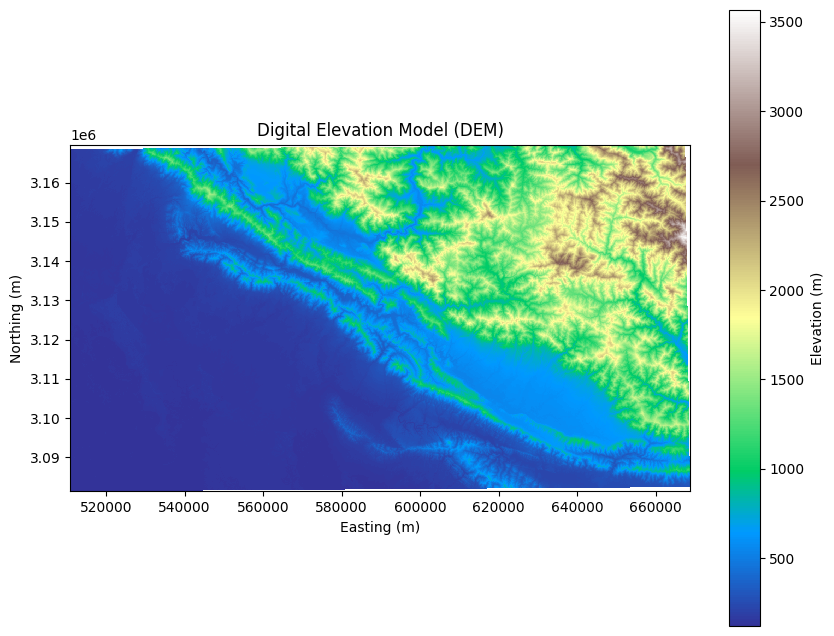

In [7]:
import rioxarray
import matplotlib.pyplot as plt

# Load the reprojected DEM; masked=True turns the no-data value (-32768) into NaN
dem_to_show = rioxarray.open_rasterio("dem_utm.tif", masked=True).squeeze("band", drop=True)
print(f"elevation range: {float(dem_to_show.min()):,.0f} – {float(dem_to_show.max()):,.0f} m")

plt.figure(figsize=(10, 8))
dem_to_show.plot(cmap='terrain', vmin=float(dem_to_show.min()), vmax=float(dem_to_show.max()),
                 cbar_kwargs={'label': 'Elevation (m)'})
plt.title('Digital Elevation Model (DEM)')
plt.xlabel('Easting (m)')
plt.ylabel('Northing (m)')
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

### 4b · Condition the DEM — fill, then **prove** it

Filling changes the terrain only where water would otherwise be trapped. We map **where** and **how deep** the DEM was filled, and **assert** that no sinks remain and every cell has a flow direction. `dem_filled.tif` is saved for reference; `dem_utm.tif` stays **unfilled** — later labs use real elevations (e.g. temperature lapse rates), never the filled surface.

DEM cells: 1,693,563 | filled: 72,766 (4.30%) | max fill depth: 70.0 m
sinks before: 72553 | sinks remaining: 0 | interior cells without a flow direction: 0
✅ conditioned: no sinks, every cell drains → saved dem_filled.tif


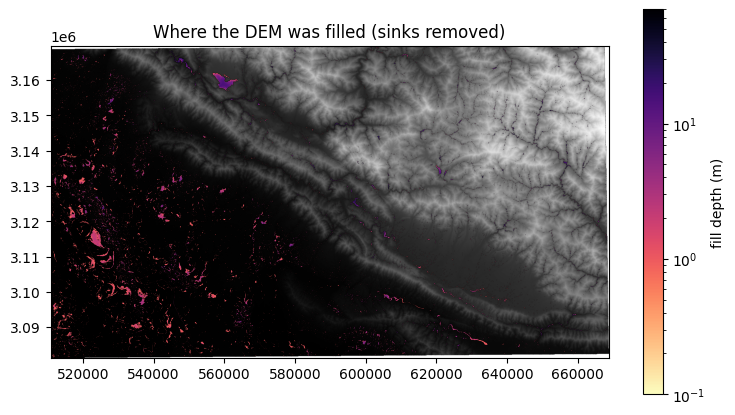

In [8]:
st = kw.check_conditioning('dem_utm.tif', filled_out='dem_filled.tif' if FILL_DEM else None)
print(f"DEM cells: {st['cells']:,} | filled: {st['filled_cells']:,} ({st['filled_pct']:.2f}%) | max fill depth: {st['max_fill_m']} m")
print(f"sinks before: {st['sinks_before']} | sinks remaining: {st['sinks_after']} | interior cells without a flow direction: {st['no_flowdir_cells']}")
assert st['sinks_after'] in (0, None) and st['no_flowdir_cells'] == 0, 'DEM is NOT hydrologically conditioned — do not delineate on it.'
print('✅ conditioned: no sinks, every cell drains' + (' → saved dem_filled.tif' if FILL_DEM else ''))
with rasterio.open('dem_utm.tif') as d:
    z = d.read(1, masked=True); b = d.bounds
ext = (b.left, b.right, b.bottom, b.top)
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(z, extent=ext, cmap='Greys_r')
im = ax.imshow(np.ma.masked_less_equal(st['depth'], 0.05), extent=ext, cmap='magma_r',
               norm=LogNorm(vmin=0.1, vmax=max(1, st['max_fill_m'])))
plt.colorbar(im, label='fill depth (m)'); ax.set_title('Where the DEM was filled (sinks removed)'); plt.show()

**🔎 Optional — what if we had not filled?** Delineate the CONFIG outlet on the raw DEM and compare. On real DEMs the unfilled basin is usually smaller or fragmented: sinks swallow the upstream area.

In [9]:
r_fill = delineate_filled("dem_utm.tif", GAUGE_LON, GAUGE_LAT, UTM, ACC_MIN, out="_tmp_filled.tif", fill=True)
a = lambda r: float(r["mask"].sum()) * DEM_RES**2 / 1e6
print(f"filled DEM: {a(r_fill):,.0f} km²")
try:
    r_raw = delineate_filled("dem_utm.tif", GAUGE_LON, GAUGE_LAT, UTM, ACC_MIN, out="_tmp_raw.tif", fill=False)
    print(f"raw DEM:    {a(r_raw):,.0f} km²  ({100*(a(r_raw)/a(r_fill)-1):+.1f}%) ")
except ValueError as e:
    print("raw DEM:    delineation FAILED —", e)

filled DEM: 3,379 km²
raw DEM:    delineation FAILED — No cell has more than acc_min=5000 upstream cells (raw DEM: sinks break the stream network) — lower acc_min, or check the DEM.


## 5 · 🖱️ Refine at 90 m — adjust, then export the map to PDF

Same controls, now on the **filled 90 m DEM** of your basin: nudge the marker, tune **ACC_MIN**, press **Delineate**.

- **Save map → PDF** writes `basin_map.pdf` (DEM + basin outline + outlet) — a clean figure for a report (downloads on Colab).
- **Export basin** writes `basin.geojson` + `basin_mask_30m.tif` (and downloads them on Colab).

When you're happy, copy the printed `GAUGE_LON, GAUGE_LAT` (and `ACC_MIN`) into §2 and **Restart & Run All** — §6–9 then freeze exactly that basin for Labs 2–6.

In [10]:
# --- interactive outlet picker + live delineation + PDF/vector export ---
import ee, geemap, ipywidgets as W
from ipyleaflet import Marker, CircleMarker
from IPython.display import display
try: ee.Initialize(project=EE_PROJECT)
except Exception: ee.Authenticate(); ee.Initialize(project=EE_PROJECT)

region = ee.Geometry.Rectangle(BBOX)
dem_ee = ee.ImageCollection('COPERNICUS/DEM/GLO30_2024_1').select('DEM').mosaic()
hill   = ee.Terrain.hillshade(dem_ee)
rivers = ee.FeatureCollection('WWF/HydroSHEDS/v1/FreeFlowingRivers').filterBounds(region)

M = geemap.Map(basemap='Esri.WorldImagery', center=[GAUGE_LAT, GAUGE_LON], zoom=10)
M.addLayer(hill, {'min':0,'max':255}, 'Hillshade', True)
M.addLayer(dem_ee, {'min':100,'max':7000,
                    'palette':['#2b83ba','#abdda4','#ffffbf','#fdae61','#d7191c']}, 'Elevation (m)', False)
M.addLayer(rivers, {'color':'1f78ff'}, 'Rivers (HydroSHEDS)', True)
M.addLayer(region, {'color':'ffffff'}, 'Basin box', False)

outlet = {'lon': GAUGE_LON, 'lat': GAUGE_LAT}
state  = {'gj': None, 'km2': None}          # last delineation, for export
mk = Marker(location=(GAUGE_LAT, GAUGE_LON), draggable=True, title='Outlet — drag onto the river')
M.add(mk)
def _mv(change): outlet['lat'], outlet['lon'] = float(mk.location[0]), float(mk.location[1])
mk.observe(_mv, names='location')
def _clk(**k):
    if k.get('type') == 'click': mk.location = (k['coordinates'][0], k['coordinates'][1])
M.on_interaction(_clk)

acc = W.FloatLogSlider(value=ACC_MIN, base=10, min=3, max=6.5, step=0.1, description='ACC_MIN',
                       readout_format='.0f', continuous_update=False)   # re-runs when released
b_run = W.Button(description='Delineate',       button_style='success', icon='play')
b_pdf = W.Button(description='Save map → PDF',   button_style='primary', icon='file-pdf-o')
b_exp = W.Button(description='Export basin',     button_style='info',    icon='download')
out = W.Output()

def _run(_):
    with out:
        out.clear_output()
        from rasterio.features import shapes
        from shapely.geometry import shape, mapping
        from shapely.ops import unary_union, transform as shp_transform
        from pyproj import Transformer
        with rasterio.open('dem_utm.tif') as _s: _b = _s.bounds
        _x, _y = Transformer.from_crs('EPSG:4326', UTM, always_xy=True).transform(outlet['lon'], outlet['lat'])
        if not (_b.left < _x < _b.right and _b.bottom < _y < _b.top):
            print('⚠️ outlet is outside the downloaded 90 m DEM — preview it in §3, then re-run §4.'); return
        try:
            res = kw.delineate('dem_utm.tif', outlet['lon'], outlet['lat'], UTM, int(acc.value), out='basin_mask_30m.tif')
        except (ValueError, RuntimeError) as e:
            print('⚠️', e); return
        r  = rioxarray.open_rasterio('basin_mask_30m.tif').squeeze('band', drop=True)
        a  = (r.values == 1).astype('uint8'); tr = r.rio.transform()
        geoms = [shape(g) for g, v in shapes(a, mask=a == 1, transform=tr) if v == 1]
        to_ll = Transformer.from_crs(UTM, 'EPSG:4326', always_xy=True).transform
        gj = {'type':'Feature','properties':{},'geometry':mapping(shp_transform(to_ll, unary_union(geoms)))}
        for lyr in list(M.layers):
            if getattr(lyr, 'name', '') in ('Basin','Snapped outlet','Streams (ACC_MIN)'): M.remove_layer(lyr)
        M.add_geojson(streams_geojson(res['acc'], res['fdir'], 'dem_utm.tif', int(acc.value)), layer_name='Streams (ACC_MIN)',
                      style={'color': '#29B6F6', 'weight': 1.5, 'opacity': 0.9})
        M.add_geojson(gj, layer_name='Basin', style={'color':'#e9a63b','weight':2,'fillColor':'#e9a63b','fillOpacity':0.15})
        sx, sy = res['snap']; solon, solat = to_ll(sx, sy)
        M.add(CircleMarker(location=(solat, solon), radius=6, color='red', fill_color='red', name='Snapped outlet'))
        km2 = float(a.sum()) * abs(tr.a * tr.e) / 1e6
        state['gj'] = gj; state['km2'] = km2
        print(f'basin area ≈ {km2:,.0f} km²  |  snapped outlet lon={solon:.4f}, lat={solat:.4f}')
        print('   ' + snap_report(res, 'dem_utm.tif', int(acc.value)))
        print(f'Happy with it? set  GAUGE_LON, GAUGE_LAT = {outlet["lon"]:.4f}, {outlet["lat"]:.4f}  ·  ACC_MIN = {int(acc.value)}  and Restart & Run All.')

def _save_pdf(_):
    with out:
        if not os.path.exists('basin_mask_30m.tif'):
            print('Delineate first, then Save map → PDF.'); return
        from pyproj import Transformer
        dem = rioxarray.open_rasterio('dem_utm.tif', masked=True).squeeze('band', drop=True)
        m   = rioxarray.open_rasterio('basin_mask_30m.tif').squeeze('band', drop=True)
        fig, ax = plt.subplots(figsize=(7.5, 7.5))
        dem.plot(ax=ax, cmap='terrain', cbar_kwargs={'label':'elevation (m)'})
        m.where(m==1).plot(ax=ax, cmap='autumn', alpha=0.4, add_colorbar=False)
        ox, oy = Transformer.from_crs('EPSG:4326', UTM, always_xy=True).transform(outlet['lon'], outlet['lat'])
        ax.plot(ox, oy, 'b*', ms=16, label='outlet')
        km2 = state['km2'] or float((np.asarray(m)==1).sum())*abs(m.rio.transform().a*m.rio.transform().e)/1e6
        ax.set_title(f"West Rapti basin — outlet {outlet['lat']:.3f}N {outlet['lon']:.3f}E — {km2:,.0f} km²")
        ax.set_aspect('equal'); ax.legend(loc='upper right')
        fig.savefig('basin_map.pdf', bbox_inches='tight', dpi=200); plt.close(fig)
        print('saved basin_map.pdf')
        if IN_COLAB:
            from google.colab import files; files.download('basin_map.pdf')

def _export(_):
    with out:
        import json as _json
        if state['gj'] is None:
            print('Delineate first, then Export basin.'); return
        _json.dump(state['gj'], open('basin.geojson','w'))
        print('saved basin.geojson + basin_mask_30m.tif')
        if IN_COLAB:
            from google.colab import files
            files.download('basin.geojson'); files.download('basin_mask_30m.tif')

b_run.on_click(_run); b_pdf.on_click(_save_pdf); b_exp.on_click(_export)
acc.observe(lambda ch: _run(None), names='value')        # slider re-runs the delineation
display(W.HBox([acc, b_run, b_pdf, b_exp])); display(out)
M

Output()

Map(center=[28.1727, 81.372], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprig…

### ✅ Checkpoint 2 — refined basin
Edges follow ridgelines at 90 m; the area is close to the 500 m preview (a few % difference is normal). Then copy the printed `GAUGE_LON, GAUGE_LAT` and `ACC_MIN` into §2 and **Restart & Run All** to freeze via §6–9.

## 6 · Freeze the delineation from CONFIG  (reproducible — runs on *Restart & Run All*)

The map above is for *choosing*; this cell re-delineates deterministically from the `GAUGE_LON/LAT` in §2,
so the frozen basin does not depend on any click. Labs 2–6 read what §6–9 save.

delineated on the filled DEM (kw.delineate fills sinks first)


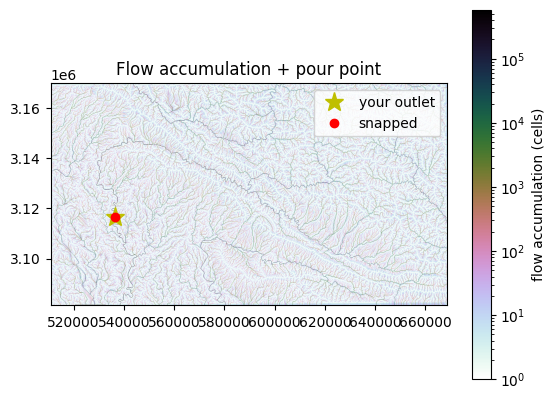

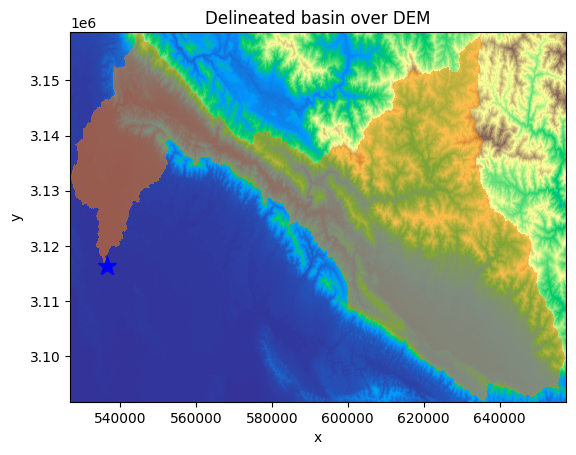

In [11]:
r = kw.delineate("dem_utm.tif", GAUGE_LON, GAUGE_LAT, UTM, ACC_MIN)
gx, gy = r["gauge"]; xs, ys = r["snap"]
print("delineated on the filled DEM (kw.delineate fills sinks first)")
dem = rioxarray.open_rasterio("dem_utm.tif", masked=True).squeeze("band", drop=True)
plt.imshow(r["acc"], extent=r["extent"], norm=LogNorm(vmin=1), cmap="cubehelix_r")
plt.colorbar(label="flow accumulation (cells)")
plt.plot(gx, gy, "y*", ms=14, label="your outlet"); plt.plot(xs, ys, "r.", ms=12, label="snapped")
plt.legend(); plt.title("Flow accumulation + pour point"); plt.show()
mask30 = rioxarray.open_rasterio("basin_mask_30m.tif").squeeze("band", drop=True)
fig, ax = plt.subplots()
dem.plot(ax=ax, cmap="terrain", add_colorbar=False)
mask30.where(mask30==1).plot(ax=ax, cmap="autumn", alpha=0.5, add_colorbar=False)
ax.plot(gx, gy, "b*", ms=14); ax.set_title("Delineated basin over DEM"); plt.show()

## 7 · Canonical WA+ grid + NetCDF

Every future layer must line up exactly, so we snap the basin onto one master grid (300 m, UTM 44N, EPSG:32644).

basin = 37552 cells @ 300 m (3379.7 km2)


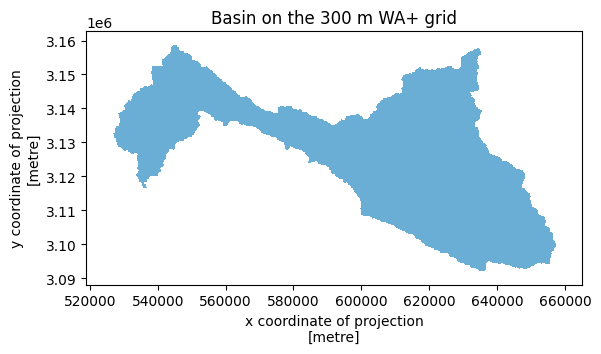

gridspec: {'crs': 'EPSG:32644', 'res': 300, 'te': [510600.0, 3081300.0, 669000.0, 3169800.0], 'width': 528, 'height': 295}


In [12]:
gs = kw.build_wa_grid("dem_utm.tif", WA_RES, UTM, te=GRID_TE)
m300 = kw.warp_mask("basin_mask_30m.tif", gs, UTM)
cells = int(np.asarray(m300).sum()); print(f"basin = {cells} cells @ {WA_RES} m ({cells*WA_RES**2/1e6:.1f} km2)")
basin = m300.where(m300==1, drop=True)          # crop to basin bbox -> auto-zoom
basin.plot(cmap="Blues", add_colorbar=False); ax = plt.gca(); ax.set_aspect("equal")
x0,x1=ax.get_xlim(); y0,y1=ax.get_ylim(); mx,my=0.06*abs(x1-x0),0.06*abs(y1-y0)
ax.set_xlim(x0-mx*np.sign(x1-x0), x1+mx*np.sign(x1-x0)); ax.set_ylim(y0-my*np.sign(y1-y0), y1+my*np.sign(y1-y0))
plt.title(f"Basin on the {WA_RES} m WA+ grid"); plt.show()
print("gridspec:", gs)

### ✅ Checkpoint 3
`gridspec.json` is the shared grid. Every team warps its sub-catchment mask to THIS spec — do not recompute per team.

## 8 · BASIN skeleton
`BASIN` is the one dictionary the whole pipeline reads — an empty shell now, filled by later labs.

In [13]:
BASIN = kw.write_basin(name="West_Rapti")
BASIN

{'name': 'West_Rapti',
 'hydroyear': 10,
 'chunksize': 1000,
 'unit_conversion': 1000.0,
 'gis_data': {'basin_mask': 'basin_mask.nc',
  'dem': 'dem_utm.tif',
  'aeisw': None,
  'population': None,
  'wpl': None,
  'environ_water_req': None},
 'data_cube': {'monthly': {'p': None,
   'et': None,
   'etref': None,
   'i': None,
   'nrd': None,
   'lai': None,
   'ndm': None,
   'sro': None,
   'etincr': None,
   'etrain': None,
   'perc': None}}}

## 9 · Verify & save to Drive
Colab wipes its disk on disconnect, so copy the outputs to Drive (`OUT_DIR`). Later labs pull them back
with `kw.load_inputs([...], OUT_DIR)` — `gridspec.json` and `basin_config.json` especially, which Lab 2 needs.

In [14]:
saved = kw.save_outputs(
    ["dem_utm.tif","dem_filled.tif","basin_mask_30m.tif","basin_mask_300m.tif",
     "basin_mask.nc","gridspec.json","basin_config.json"], OUT_DIR)
print("saved to", OUT_DIR, "->", saved)

saved to /content/drive/MyDrive/west_rapti/outputs -> ['dem_utm.tif', 'dem_filled.tif', 'basin_mask_30m.tif', 'basin_mask_300m.tif', 'basin_mask.nc', 'gridspec.json', 'basin_config.json']
